In [ ]:
# Install dependencies (if not already installed)
!pip install spacy transformers torch numpy seaborn matplotlib scikit-learn requests
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 22.9 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
from google.colab import files

uploaded = files.upload()  # Select the file manually
lexicon_file = "NRC-Emotion-Lexicon-Wordlevel-v0.92.txt"  # Use the uploaded file

Saving NRC-Emotion-Lexicon-Wordlevel-v0.92.txt to NRC-Emotion-Lexicon-Wordlevel-v0.92.txt


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!



Enter your poem:
A smile forms, yet tears still fall, A lonely heart, yet standing tall. The past still whispers, memories cling, Yet hope remains in birds that sing.  Love is bitter, love is sweet, A dance of loss and joy we meet. Pain and laughter, hand in hand, Through tides of life, we understand.

Processed words:
 smile forms yet tears still fall lonely heart yet standing tall past still whispers memories cling yet hope remains birds sing love bitter love sweet dance loss joy meet pain laughter hand hand tides life understand

Sliding windows:
Window 1: smile forms yet tears still fall lonely heart yet standing tall past still whispers memories cling yet hope remains birds
Window 2: tall past still whispers memories cling yet hope remains birds sing love bitter love sweet dance loss joy meet pain
Window 3: sing love bitter love sweet dance loss joy meet pain laughter hand hand tides life understand
Window 4: laughter hand hand tides life understand

Transformer-Based Emotion Ana

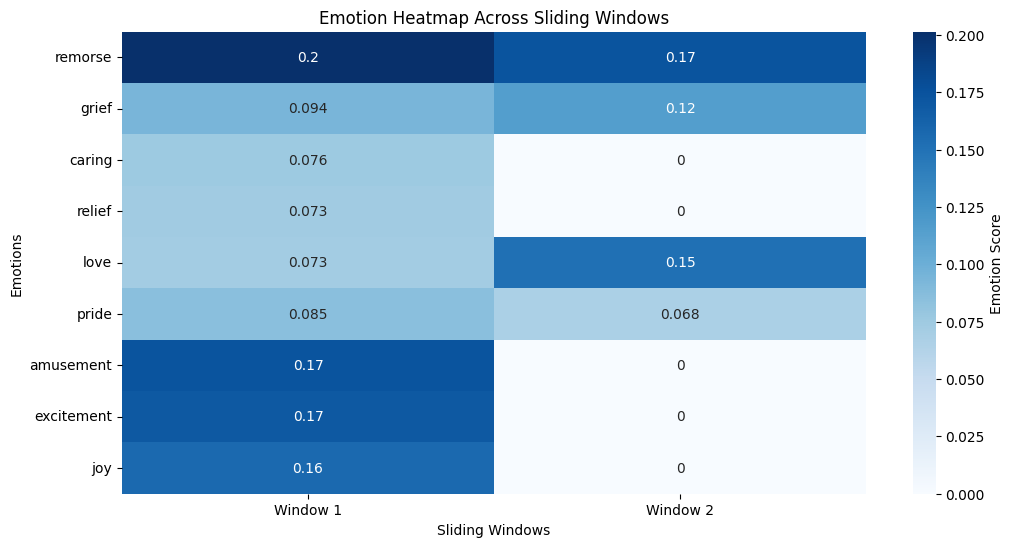

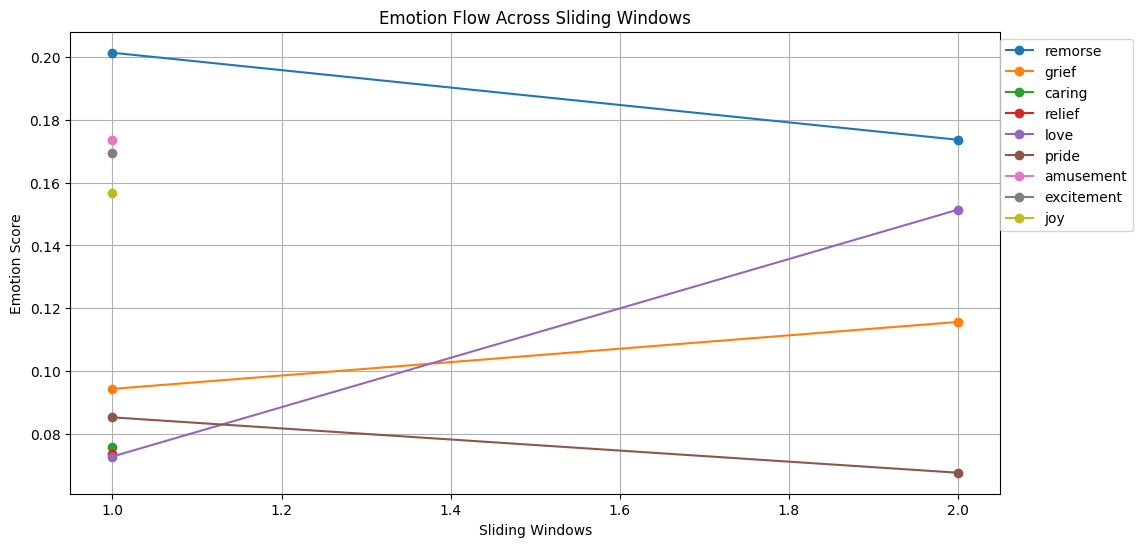


Lexicon-Based Emotion Detection Result: positive

Would you like to analyze another poem? (yes/no): no
Goodbye!


In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import nltk
from nltk.corpus import stopwords
from collections import defaultdict
import pandas as pd
from nltk.tokenize import word_tokenize
from google.colab import files
import os
import requests
import json
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Load necessary resources
nltk.download('stopwords')
nltk.download('punkt')

# Load model
def load_model():
    model_name = "joeddav/distilbert-base-uncased-go-emotions-student"
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name)
    return tokenizer, model

tokenizer, model = load_model()

# Preprocess text
def preprocess_text(text):
    words = nltk.word_tokenize(text.lower())
    words = [word for word in words if word.isalnum() and word not in stopwords.words('english')]
    return " ".join(words)

def get_processed_words(text):
    processed_poem = preprocess_text(text)
    print("\nProcessed words:\n", processed_poem)
    return processed_poem

# Sliding window function
def sliding_window(text, window_size=20, step_size=10):
    words = text.split()
    return [" ".join(words[i:i+window_size]) for i in range(0, len(words), step_size)]

def get_sliding_windows(text, window_size=20, step_size=10):
    processed_poem = preprocess_text(text)
    windows = sliding_window(processed_poem, window_size, step_size)
    print("\nSliding windows:")
    for i, window in enumerate(windows):
        print(f"Window {i+1}: {window}")
    return windows

# Load NRC Emotion Lexicon
def load_nrc_lexicon(filepath):
    lexicon_df = pd.read_csv(filepath, sep="\t", names=["word", "emotion", "association"], engine='python')
    lexicon_df["association"] = pd.to_numeric(lexicon_df["association"], errors='coerce').fillna(0).astype(int)
    emotion_words = lexicon_df.pivot(index="word", columns="emotion", values="association").fillna(0)
    return emotion_words

# Lexicon-based emotion detection
def lexicon_based_emotion_analysis(poem):
    words = word_tokenize(poem)
    emotions = nrc_lexicon.loc[nrc_lexicon.index.intersection(words)].sum()
    return emotions.idxmax() if emotions.sum() > 0 else "Neutral"

# Transformer-based emotion analysis
def analyze_emotions(poem, threshold=0.065):
    inputs = tokenizer(poem, return_tensors="pt", truncation=True, padding=True)
    outputs = model(**inputs)
    scores = torch.softmax(outputs.logits, dim=1).squeeze().tolist()

    emotion_labels = ["admiration", "amusement", "anger", "annoyance", "approval", "caring", "confusion", "curiosity", "desire", "disappointment", "disapproval", "disgust", "embarrassment", "excitement", "fear", "gratitude", "grief", "joy", "love", "nervousness", "neutral", "optimism", "pride", "realization", "relief", "remorse", "sadness", "surprise"]

    if len(scores) != len(emotion_labels):
        print("Warning: Mismatch in emotion label count and model output!")
        return {}

    emotion_scores = {emotion_labels[i]: scores[i] for i in range(len(emotion_labels)) if scores[i] >= threshold}

    # Sort the emotions in descending order of score and get top 6
    sorted_emotions = sorted(emotion_scores.items(), key=lambda x: x[1], reverse=True)[:6]

    return dict(sorted_emotions)

# Heatmap plot for emotion scores across windows
def plot_emotion_heatmap(emotion_trends):
    emotions = list(emotion_trends.keys())
    windows_count = len(next(iter(emotion_trends.values())))  # Number of windows
    max_windows_count = max(len(scores) for scores in emotion_trends.values())  # Find the max length of the windows list

    # Ensure all emotion trends have the same number of windows by padding the shorter ones with zeros
    emotion_matrix = np.zeros((len(emotions), max_windows_count))

    for i, emotion in enumerate(emotions):
        scores = emotion_trends[emotion]
        emotion_matrix[i, :len(scores)] = scores  # Add scores, padding with zero if needed

    plt.figure(figsize=(12, 6))
    sns.heatmap(emotion_matrix, annot=True, xticklabels=[f"Window {i+1}" for i in range(max_windows_count)], yticklabels=emotions, cmap='Blues', cbar_kws={'label': 'Emotion Score'})
    plt.title("Emotion Heatmap Across Sliding Windows")
    plt.xlabel("Sliding Windows")
    plt.ylabel("Emotions")
    plt.show()

# Line plot for emotion flow (emotion score trend)
def plot_emotion_flow(emotion_trends):
    plt.figure(figsize=(12, 6))

    for emotion, scores in emotion_trends.items():
        plt.plot(range(1, len(scores) + 1), scores, label=emotion, marker='o')

    plt.title("Emotion Flow Across Sliding Windows")
    plt.xlabel("Sliding Windows")
    plt.ylabel("Emotion Score")
    plt.legend(loc='upper right', bbox_to_anchor=(1.15, 1))
    plt.grid(True)
    plt.show()

# User input loop
while True:
    poem = input("\nEnter your poem:\n")
    processed_poem = get_processed_words(poem)
    windows = get_sliding_windows(processed_poem)
    emotion_trends = defaultdict(list)

    for window in windows:
        emotions = analyze_emotions(window)
        for emotion, score in emotions.items():
            emotion_trends[emotion].append(score)

    print("\nTransformer-Based Emotion Analysis:")
    sorted_emotions = sorted([(e, sum(s) / len(s)) for e, s in emotion_trends.items()], key=lambda x: x[1], reverse=True)
    for emotion, avg_score in sorted_emotions:
        print(f"{emotion.capitalize()}: {avg_score:.2f}")

    # Plotting heatmap and emotion flow
    plot_emotion_heatmap(emotion_trends)
    plot_emotion_flow(emotion_trends)

    lexicon_result = lexicon_based_emotion_analysis(processed_poem)
    print("\nLexicon-Based Emotion Detection Result:", lexicon_result)

    retry = input("\nWould you like to analyze another poem? (yes/no): ").strip().lower()
    if retry != "yes":
        print("Goodbye!")
        break